# Project results analysis

This master notebook synthesizes the completed analyses from Sections 3.2 and 3.4–3.8: dataset audit, Vietnamese title processing, image features, joint visual–semantic embedding, spatially aware concept discovery, and the two prediction branches. It reads existing result artifacts and does not retrain the pipeline.

The findings describe the collected sample. Prediction scores are uncalibrated, title labels are weak supervision, and no independent image-level gold evaluation has yet been completed.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT=Path.cwd()
if not (ROOT/'fashion_vn').exists(): ROOT=ROOT.parent
BASE=ROOT/'outputs/figures'; OUT=BASE/'project_results'; OUT.mkdir(parents=True,exist_ok=True)
COLORS={'blue':'#386CB0','green':'#59A14F','orange':'#E68600','purple':'#8E63B5','red':'#CC4F4F','gray':'#929292'}
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':12,'axes.labelsize':11,'figure.titlesize':16})
def read(folder,name): return pd.read_csv(BASE/folder/name)
def savefig(fig,stem):
    fig.savefig(OUT/f'{stem}.png',dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/f'{stem}.svg',bbox_inches='tight',facecolor='white')
    plt.show(); plt.close(fig)
dataset=read('dataset_audit','3_2_2_dataset_summary.csv')
titles=read('title_processing','3_4_1_processing_overview.csv')
vocab=read('title_processing','3_4_7_vocabulary.csv')
images=read('image_features','3_5_1_processing_coverage.csv')
cache=read('image_features','3_5_4_cache_summary.csv')
vse=read('joint_embedding','3_6_validation_alignment_metrics.csv')
concepts=read('spatial_concepts','3_7_1_category_summary.csv')
coverage=read('prediction_branches','3_8_3_category_coverage.csv')
groups=read('prediction_branches','3_8_5_attribute_group_counts.csv')
overlap=read('prediction_branches','3_8_7_cross_branch_overlap.csv')
schema_summary=json.loads((ROOT/'outputs/predictions/summary.json').read_text(encoding='utf-8'))
disc_summary=json.loads((ROOT/'outputs/predictions_discovered/summary.json').read_text(encoding='utf-8'))
N=int(dataset.iloc[0]['count']); print(f'Loaded project results for {N:,} products')

Loaded project results for 10,798 products


## 1. End-to-end pipeline retention

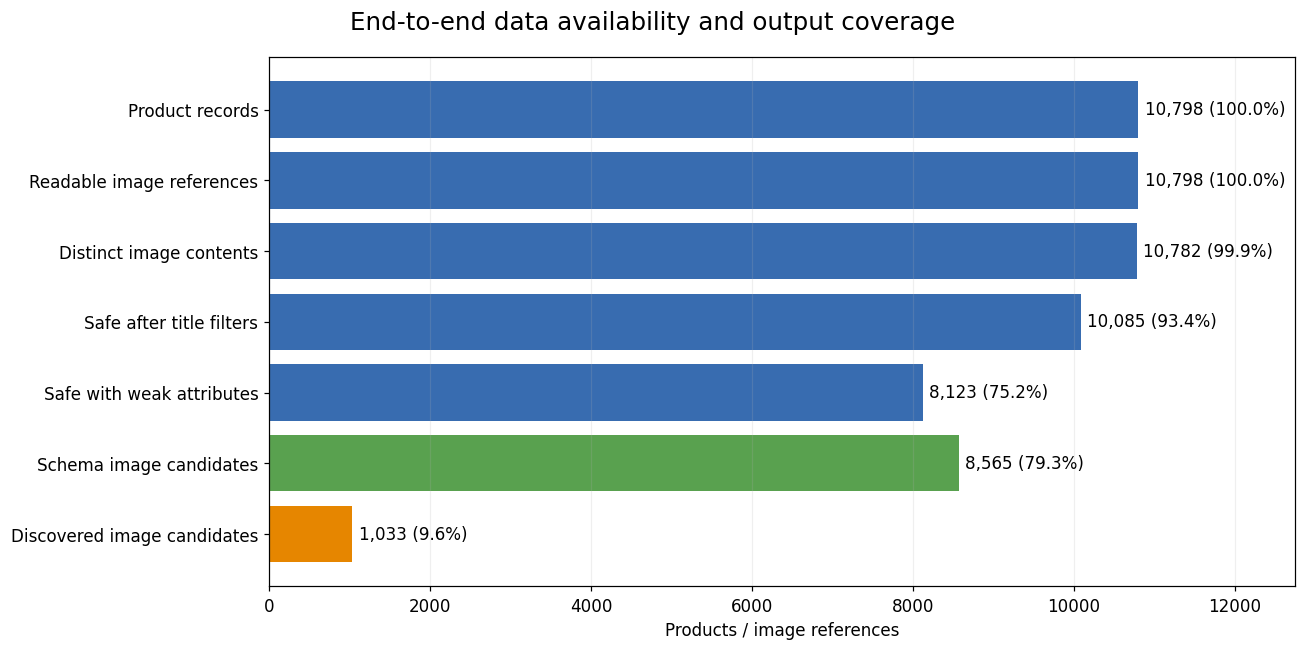

In [2]:
stages=pd.DataFrame([
 ('Product records',N),
 ('Readable image references',int(dataset.loc[dataset.indicator=='Referenced and readable images','count'].iloc[0])),
 ('Distinct image contents',int(dataset.loc[dataset.indicator=='Distinct images by SHA-256','count'].iloc[0])),
 ('Safe after title filters',int(titles.loc[titles.indicator=='Retained after ambiguity filters','count'].iloc[0])),
 ('Safe with weak attributes',int(titles.loc[titles.indicator=='Retained with ≥1 weak attribute','count'].iloc[0])),
 ('Schema image candidates',schema_summary['products_with_image_candidates']),
 ('Discovered image candidates',disc_summary['products_with_image_candidates'])],columns=['stage','count'])
stages['percent']=100*stages['count']/N; stages.to_csv(OUT/'project_pipeline_retention.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(12,6)); ordered=stages.iloc[::-1]; colors=[COLORS['orange'] if 'Discovered' in s else COLORS['green'] if 'Schema' in s else COLORS['blue'] for s in ordered.stage]
bars=ax.barh(ordered.stage,ordered['count'],color=colors)
for b,(_,r) in zip(bars,ordered.iterrows()): ax.text(r['count']+80,b.get_y()+b.get_height()/2,f"{r['count']:,} ({r['percent']:.1f}%)",va='center')
ax.set_xlim(0,N*1.18); ax.set_xlabel('Products / image references'); ax.grid(axis='x',alpha=.2)
fig.suptitle('End-to-end data availability and output coverage')
fig.tight_layout(); savefig(fig,'project_figure_1_pipeline_retention')

## 2. Dataset, text, and image representation summary

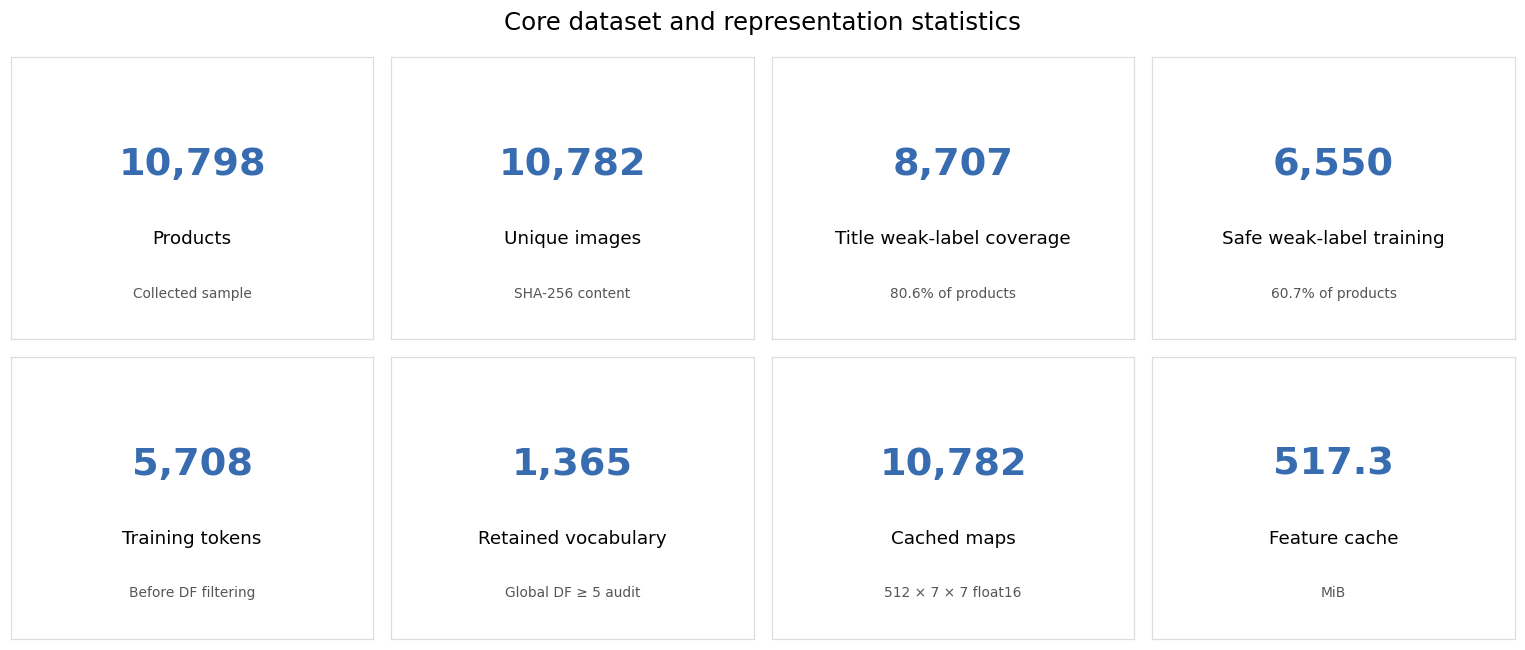

In [3]:
cards=[
 ('Products',N,'Collected sample'),('Unique images',10782,'SHA-256 content'),
 ('Title weak-label coverage',8707,'80.6% of products'),('Safe weak-label training',6550,'60.7% of products'),
 ('Training tokens',5708,'Before DF filtering'),('Retained vocabulary',1365,'Global DF ≥ 5 audit'),
 ('Cached maps',int(cache.cached_maps.iloc[0]),'512 × 7 × 7 float16'),('Feature cache',float(cache.total_disk_mib.iloc[0]),'MiB')
]
fig,axes=plt.subplots(2,4,figsize=(14,6)); axes=axes.ravel()
for ax,(label,value,note) in zip(axes,cards):
    shown=f'{value:,.1f}' if isinstance(value,float) and not value.is_integer() else f'{value:,.0f}'
    ax.text(.5,.62,shown,ha='center',va='center',fontsize=25,fontweight='bold',color=COLORS['blue'])
    ax.text(.5,.34,label,ha='center',fontsize=12); ax.text(.5,.15,note,ha='center',fontsize=9,color='#555555'); ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_color('#DDDDDD')
fig.suptitle('Core dataset and representation statistics')
fig.tight_layout(); savefig(fig,'project_figure_2_core_statistics')

## 3. Visual–semantic embedding results

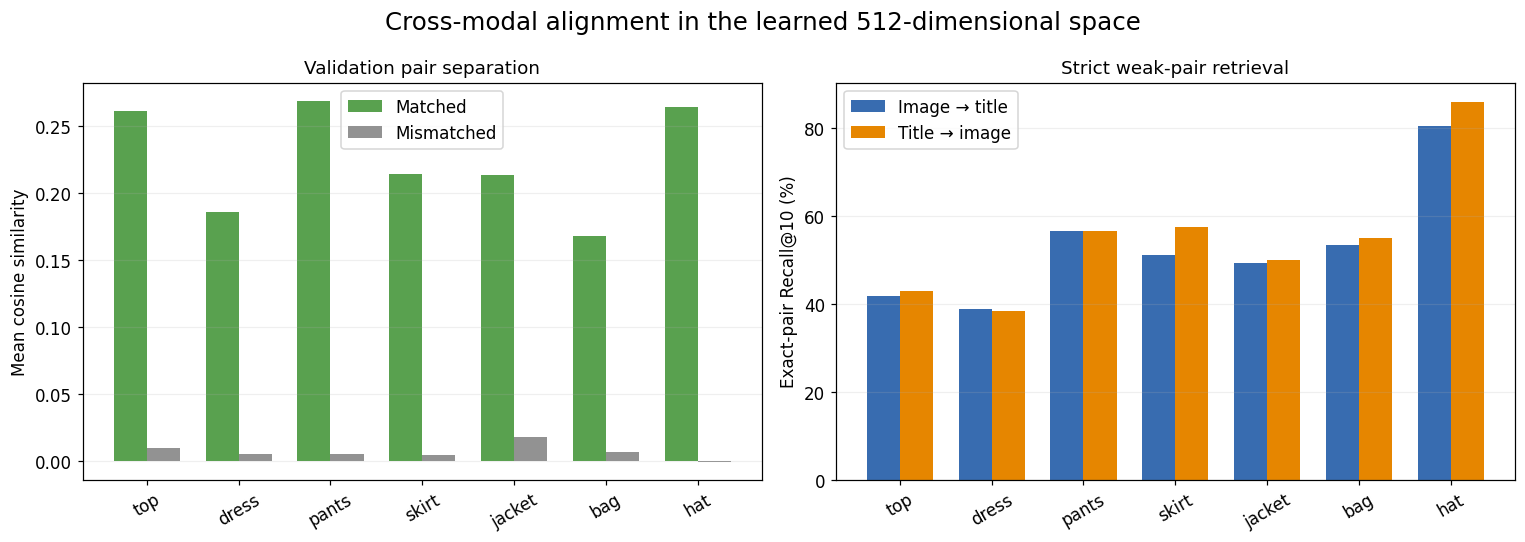

In [4]:
fig,axes=plt.subplots(1,2,figsize=(14,5)); x=np.arange(len(vse)); w=.36
axes[0].bar(x-w/2,vse.positive_cosine_mean,w,label='Matched',color=COLORS['green']); axes[0].bar(x+w/2,vse.negative_cosine_mean,w,label='Mismatched',color=COLORS['gray'])
axes[0].set_xticks(x,vse.category,rotation=30); axes[0].set_ylabel('Mean cosine similarity'); axes[0].set_title('Validation pair separation'); axes[0].legend(); axes[0].grid(axis='y',alpha=.2)
axes[1].bar(x-w/2,100*vse.i2t_R10,w,label='Image → title',color=COLORS['blue']); axes[1].bar(x+w/2,100*vse.t2i_R10,w,label='Title → image',color=COLORS['orange'])
axes[1].set_xticks(x,vse.category,rotation=30); axes[1].set_ylabel('Exact-pair Recall@10 (%)'); axes[1].set_title('Strict weak-pair retrieval'); axes[1].legend(); axes[1].grid(axis='y',alpha=.2)
fig.suptitle('Cross-modal alignment in the learned 512-dimensional space')
fig.tight_layout(); savefig(fig,'project_figure_3_vse_results')

## 4. Concept discovery capacity

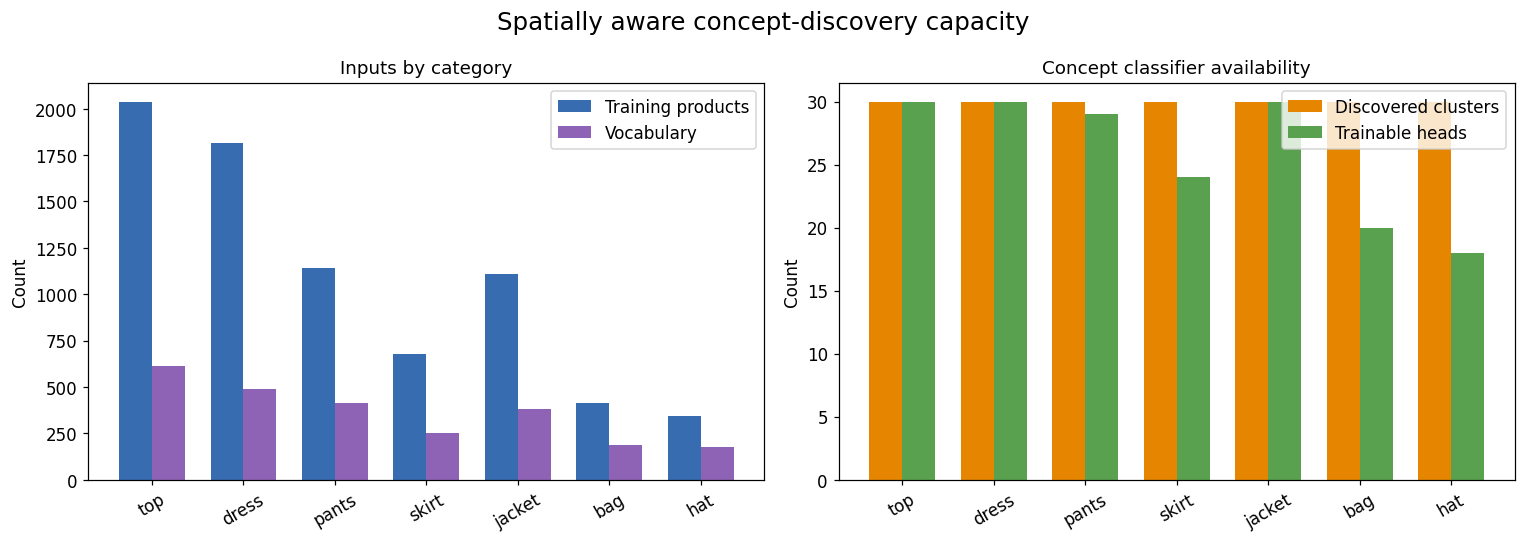

In [5]:
fig,axes=plt.subplots(1,2,figsize=(14,5)); x=np.arange(len(concepts)); w=.36
axes[0].bar(x-w/2,concepts.train_products,w,label='Training products',color=COLORS['blue']); axes[0].bar(x+w/2,concepts.vocabulary,w,label='Vocabulary',color=COLORS['purple'])
axes[0].set_xticks(x,concepts.category,rotation=30); axes[0].set_ylabel('Count'); axes[0].legend(); axes[0].set_title('Inputs by category')
axes[1].bar(x-w/2,concepts.discovered_concepts,w,label='Discovered clusters',color=COLORS['orange']); axes[1].bar(x+w/2,concepts.trained_heads,w,label='Trainable heads',color=COLORS['green'])
axes[1].set_xticks(x,concepts.category,rotation=30); axes[1].set_ylabel('Count'); axes[1].legend(); axes[1].set_title('Concept classifier availability')
fig.suptitle('Spatially aware concept-discovery capacity')
fig.tight_layout(); savefig(fig,'project_figure_4_concept_capacity')

## 5. Two prediction branches

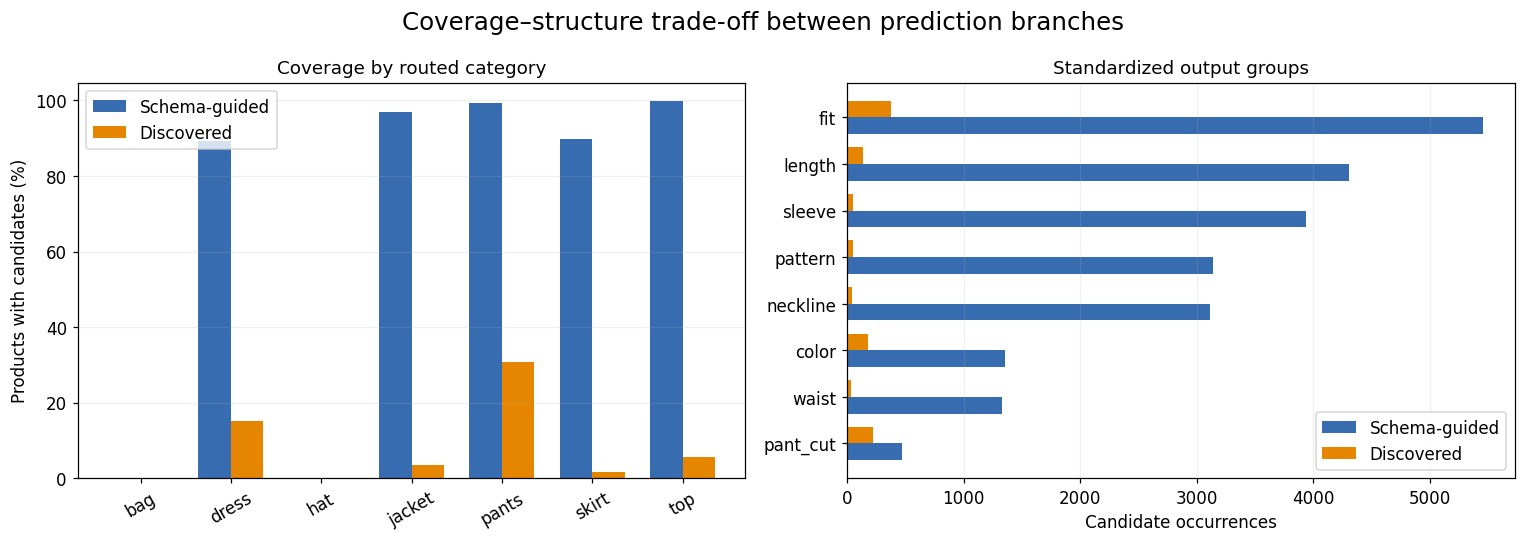

In [6]:
usable=coverage[coverage.category.isin(concepts.category)]
fig,axes=plt.subplots(1,2,figsize=(14,5)); x=np.arange(len(usable)); w=.36
axes[0].bar(x-w/2,100*usable.schema_rate,w,label='Schema-guided',color=COLORS['blue']); axes[0].bar(x+w/2,100*usable.discovered_rate,w,label='Discovered',color=COLORS['orange'])
axes[0].set_xticks(x,usable.category,rotation=30); axes[0].set_ylabel('Products with candidates (%)'); axes[0].set_title('Coverage by routed category'); axes[0].legend(); axes[0].grid(axis='y',alpha=.2)
ordered=groups.sort_values('schema'); y=np.arange(len(ordered)); h=.36
axes[1].barh(y-h/2,ordered.schema,h,label='Schema-guided',color=COLORS['blue']); axes[1].barh(y+h/2,ordered.discovered,h,label='Discovered',color=COLORS['orange'])
axes[1].set_yticks(y,ordered.group); axes[1].set_xlabel('Candidate occurrences'); axes[1].set_title('Standardized output groups'); axes[1].legend(); axes[1].grid(axis='x',alpha=.2)
fig.suptitle('Coverage–structure trade-off between prediction branches')
fig.tight_layout(); savefig(fig,'project_figure_5_prediction_branches')

## 6. Main findings and interpretation boundaries

In [7]:
weighted_gap=np.average(vse.cosine_gap,weights=vse.validation_pairs)
both=int(overlap.loc[overlap.outcome=='Both branches','products'].iloc[0])
findings=pd.DataFrame([
 ('Data completeness',f'{N:,} readable image references and {10782:,} distinct image contents','Strong technical completeness for this sample; no population-representativeness claim.'),
 ('Weak-label availability','8,707 products contain at least one title-derived attribute group','Labels describe seller claims and may be missing, noisy, or non-visual.'),
 ('Image representation','10,782 cached 512×7×7 feature maps','Frozen ImageNet features retain coarse spatial information but show central-image bias.'),
 ('Cross-modal alignment',f'Weighted matched–mismatched cosine gap = {weighted_gap:.3f}','Positive separation exists, while similarity distributions still overlap.'),
 ('Concept discovery',f"{int(concepts.discovered_concepts.sum())} clusters and {int(concepts.trained_heads.sum())} trainable heads",'Clusters mix attributes and noisy terms and require manual review.'),
 ('Schema branch',f"{schema_summary['products_with_image_candidates']:,} products covered ({100*schema_summary['products_with_image_candidates']/N:.1f}%)",'High coverage does not establish accuracy; scores are uncalibrated.'),
 ('Discovered branch',f"{disc_summary['products_with_image_candidates']:,} products covered ({100*disc_summary['products_with_image_candidates']/N:.1f}%)",'Conservative standardized output reflects unmapped and mixed discovered clusters.'),
 ('Branch overlap',f'{both:,} products receive candidates from both branches','Candidate agreement must be evaluated against independent image-level gold labels.')],
 columns=['topic','observed_result','interpretation_boundary'])
findings.to_csv(OUT/'project_findings_and_boundaries.csv',index=False,encoding='utf-8-sig'); display(findings)

,topic,observed_result,interpretation_boundary
0,Data completeness,"10,798 readable image references and 10,782 di...",Strong technical completeness for this sample;...
1,Weak-label availability,"8,707 products contain at least one title-deri...",Labels describe seller claims and may be missi...
2,Image representation,"10,782 cached 512×7×7 feature maps",Frozen ImageNet features retain coarse spatial...
3,Cross-modal alignment,Weighted matched–mismatched cosine gap = 0.221,"Positive separation exists, while similarity d..."
4,Concept discovery,210 clusters and 181 trainable heads,Clusters mix attributes and noisy terms and re...
5,Schema branch,"8,565 products covered (79.3%)",High coverage does not establish accuracy; sco...
6,Discovered branch,"1,033 products covered (9.6%)",Conservative standardized output reflects unma...
7,Branch overlap,"1,024 products receive candidates from both br...",Candidate agreement must be evaluated against ...


## 7. Report-ready synthesis

In [8]:
print(f"The project processed {N:,} local e-commerce product records with complete readable image references and {10782:,} distinct image contents. Vietnamese title processing yielded at least one seller-derived attribute group for 8,707 products, while ambiguity filtering retained 8,123 products with weak attributes. A frozen ImageNet-1K ResNet18 encoded each unique image into a 512×7×7 feature map. Seven category-specific visual–semantic embedding models showed a validation-pair-weighted matched–mismatched cosine separation of {weighted_gap:.3f}. Spatial–semantic clustering generated {int(concepts.discovered_concepts.sum())} exploratory concepts and {int(concepts.trained_heads.sum())} trainable concept classifiers. At the uncalibrated 0.70 score and 0.15 margin thresholds, the schema-guided branch emitted standardized image candidates for {schema_summary['products_with_image_candidates']:,} products, compared with {disc_summary['products_with_image_candidates']:,} for the discovered-concept branch. These results demonstrate technical feasibility and measurable image–title alignment, but attribute accuracy remains undetermined until both branches are tested against independently annotated image-level gold labels.")
print('\nGenerated master outputs:')
for p in sorted(OUT.iterdir()): print(' -',p.relative_to(ROOT))

The project processed 10,798 local e-commerce product records with complete readable image references and 10,782 distinct image contents. Vietnamese title processing yielded at least one seller-derived attribute group for 8,707 products, while ambiguity filtering retained 8,123 products with weak attributes. A frozen ImageNet-1K ResNet18 encoded each unique image into a 512×7×7 feature map. Seven category-specific visual–semantic embedding models showed a validation-pair-weighted matched–mismatched cosine separation of 0.221. Spatial–semantic clustering generated 210 exploratory concepts and 181 trainable concept classifiers. At the uncalibrated 0.70 score and 0.15 margin thresholds, the schema-guided branch emitted standardized image candidates for 8,565 products, compared with 1,033 for the discovered-concept branch. These results demonstrate technical feasibility and measurable image–title alignment, but attribute accuracy remains undetermined until both branches are tested against 

## Source notebooks

- `dataset_initial_audit.ipynb`
- `vietnamese_title_processing_weak_labels.ipynb`
- `image_preprocessing_feature_extraction.ipynb`
- `joint_visual_semantic_embedding.ipynb`
- `spatially_aware_concept_discovery.ipynb`
- `two_attribute_prediction_branches.ipynb`